# Backtesting

In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

TICKER = 'AAPL'

DATA_PATH = (
    Path.cwd().parent
    / "Week1 - Numpy and Pandas"
    / "ticker_data_dict.pkl"
)

if DATA_PATH.exists():
    with DATA_PATH.open('rb') as file:
        loaded_dict = pickle.load(file)
    print(f'Loaded data from {DATA_PATH}')

appl = loaded_dict[TICKER]


Loaded data from g:\My Drive\Teaching\Math 628- Fall 2026\New Github\Math_628_Fall_2026\Week1 - Numpy and Pandas\ticker_data_dict.pkl


In [2]:
from labelling import *

In [3]:
prices = appl['Close']
volatility = daily_volatility_with_log_returns(prices, 30)
filter_threshold = 1.5
moelcules = cusum_filter_events_dynamic_threshold(np.log(prices), filter_threshold * volatility)
vertical_barriers = vertical_barrier(prices, moelcules, 20)


triple_barrier_events ,tt = meta_events(prices, vertical_barriers.index, [1, 1], volatility, 0, 1, vertical_barriers)
labels = meta_labeling(triple_barrier_events, prices)

In [4]:
labels

,End Time,Return of Label,Label
event_time,,,
2005-12-29,2006-01-03,0.0462,1
2006-01-03,2006-01-06,0.0207,1
2006-01-10,2006-01-11,0.0376,1
2006-01-11,2006-01-19,-0.0579,-1
2006-01-18,2006-01-19,-0.0418,-1
...,...,...,...
2025-07-21,2025-07-30,-0.0161,-1
2025-07-30,2025-08-01,-0.0319,-1
2025-08-01,2025-08-06,0.0537,1


In [5]:
apple_new = pd.merge(appl, labels, left_index=True, right_index=True)

In [6]:
apple_new

,Close,High,Low,Open,Volume,Ticker,Sector,SMA_20,SMA_50,EMA_20,...,MACD,MACD_Signal,Return,Lag_Return_1,Lag_Return_2,Lag_Return_3,Tomorrow_Return,End Time,Return of Label,Label
Date,,,,,,,,,,,,,,,,,,,,,
2005-12-29,2.1449,2.2161,2.1440,2.2149,490025200,AAPL,Information Technology,2.1934,1.9814,2.1558,...,0.0569,0.0740,-0.0288,-0.0089,0.0120,-0.0091,0.0062,2006-01-03,0.0462,1
2006-01-03,2.2440,2.2440,2.1690,2.1729,807234400,AAPL,Information Technology,2.1970,2.0027,2.1644,...,0.0520,0.0659,0.0398,0.0062,-0.0288,-0.0089,0.0029,2006-01-06,0.0207,1
2006-01-10,2.4274,2.4583,2.2764,2.2890,2279869200,AAPL,Information Technology,2.2185,2.0637,2.2199,...,0.0678,0.0608,0.0632,-0.0033,0.0258,-0.0079,0.0376,2006-01-11,0.0376,1
2006-01-11,2.5187,2.5457,2.4794,2.5169,1493794400,AAPL,Information Technology,2.2320,2.0814,2.2483,...,0.0836,0.0653,0.0376,0.0632,-0.0033,0.0258,0.0046,2006-01-19,-0.0579,-1
2006-01-18,2.4764,2.5232,2.4571,2.4941,1200637200,AAPL,Information Technology,2.3022,2.1415,2.3404,...,0.1113,0.0907,-0.0262,-0.0103,0.0154,0.0046,-0.0418,2006-01-19,-0.0418,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-21,212.2391,215.5354,211.3901,211.8596,51377400,AAPL,Information Technology,207.7972,204.4328,208.1348,...,2.2987,2.1221,0.0062,0.0055,-0.0007,0.0050,0.0090,2025-07-30,-0.0161,-1
2025-07-30,208.8130,212.1492,207.4845,211.6598,45512500,AAPL,Information Technology,211.3996,205.1580,210.2707,...,1.9073,2.3100,-0.0105,-0.0130,0.0008,0.0006,-0.0071,2025-08-01,-0.0319,-1
2025-08-01,202.1506,213.3379,201.2716,210.6310,104434500,AAPL,Information Technology,210.5985,205.0443,209.2444,...,0.6520,1.8399,-0.0250,-0.0071,-0.0105,-0.0130,0.0048,2025-08-06,0.0537,1


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, auc)

# Assume apple_new is a pre-loaded DataFrame with your data
selected_columns = ['SMA_20', 'SMA_50', 'EMA_20', 'EMA_50', 'RSI',
                    'MACD', 'MACD_Signal', 'Return', 'Lag_Return_1',
                    'Lag_Return_2', 'Lag_Return_3']

# Filter the dataset to include only rows with label -1 and 1
apple_new = apple_new[apple_new['Label'].isin([-1, 1])]

X = apple_new[selected_columns]
y = apple_new['Label'].values

In [8]:
apple_new

,Close,High,Low,Open,Volume,Ticker,Sector,SMA_20,SMA_50,EMA_20,...,MACD,MACD_Signal,Return,Lag_Return_1,Lag_Return_2,Lag_Return_3,Tomorrow_Return,End Time,Return of Label,Label
Date,,,,,,,,,,,,,,,,,,,,,
2005-12-29,2.1449,2.2161,2.1440,2.2149,490025200,AAPL,Information Technology,2.1934,1.9814,2.1558,...,0.0569,0.0740,-0.0288,-0.0089,0.0120,-0.0091,0.0062,2006-01-03,0.0462,1
2006-01-03,2.2440,2.2440,2.1690,2.1729,807234400,AAPL,Information Technology,2.1970,2.0027,2.1644,...,0.0520,0.0659,0.0398,0.0062,-0.0288,-0.0089,0.0029,2006-01-06,0.0207,1
2006-01-10,2.4274,2.4583,2.2764,2.2890,2279869200,AAPL,Information Technology,2.2185,2.0637,2.2199,...,0.0678,0.0608,0.0632,-0.0033,0.0258,-0.0079,0.0376,2006-01-11,0.0376,1
2006-01-11,2.5187,2.5457,2.4794,2.5169,1493794400,AAPL,Information Technology,2.2320,2.0814,2.2483,...,0.0836,0.0653,0.0376,0.0632,-0.0033,0.0258,0.0046,2006-01-19,-0.0579,-1
2006-01-18,2.4764,2.5232,2.4571,2.4941,1200637200,AAPL,Information Technology,2.3022,2.1415,2.3404,...,0.1113,0.0907,-0.0262,-0.0103,0.0154,0.0046,-0.0418,2006-01-19,-0.0418,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-21,212.2391,215.5354,211.3901,211.8596,51377400,AAPL,Information Technology,207.7972,204.4328,208.1348,...,2.2987,2.1221,0.0062,0.0055,-0.0007,0.0050,0.0090,2025-07-30,-0.0161,-1
2025-07-30,208.8130,212.1492,207.4845,211.6598,45512500,AAPL,Information Technology,211.3996,205.1580,210.2707,...,1.9073,2.3100,-0.0105,-0.0130,0.0008,0.0006,-0.0071,2025-08-01,-0.0319,-1
2025-08-01,202.1506,213.3379,201.2716,210.6310,104434500,AAPL,Information Technology,210.5985,205.0443,209.2444,...,0.6520,1.8399,-0.0250,-0.0071,-0.0105,-0.0130,0.0048,2025-08-06,0.0537,1


In [9]:
from itertools import combinations
from sklearn.metrics import mean_squared_error
def combinatorial_purged_cv_indices(n_samples, n_partitions=5, k=1, purge_size=0):
    """
    Generate train-test indices for Combinatorial Purged Cross Validation.

    Parameters:
    - n_samples (int): Total number of samples.
    - n_partitions (int): Number of contiguous partitions to split the data into.
    - k (int): Number of partitions to select for the test set.
    - purge_size (int): Number of samples to exclude before and after each test partition.

    Returns:
    - List of (train_indices, test_indices) tuples.
    """
    # 1. Partition the data contiguously
    partition_size = n_samples // n_partitions
    remainder = n_samples % n_partitions
    partition_boundaries = []
    start_idx = 0
    for i in range(n_partitions):
        size = partition_size + (1 if i < remainder else 0)
        end_idx = start_idx + size
        partition_boundaries.append((start_idx, end_idx))
        start_idx = end_idx

    # 2. Generate all combinations of partitions of size k for the test set
    partition_indices = range(n_partitions)
    test_combos = list(combinations(partition_indices, k))

    folds = []
    all_indices = np.arange(n_samples)
    for combo in test_combos:
        # Build test indices from the selected partitions
        test_indices_list = []
        for part_id in combo:
            start, end = partition_boundaries[part_id]
            test_indices_list.append(np.arange(start, end))
        test_indices = np.concatenate(test_indices_list)

        # Start with all indices; remove test indices
        train_mask = np.ones(n_samples, dtype=bool)
        train_mask[test_indices] = False

        # 3. Purge a window before and after each test partition
        for part_id in combo:
            start, end = partition_boundaries[part_id]
            purge_start = max(0, start - purge_size)
            purge_end = min(n_samples, end + purge_size)
            train_mask[purge_start:purge_end] = False

        train_idx = np.where(train_mask)[0]
        folds.append((train_idx, test_indices))

    return folds


In [10]:
def compute_pl_for_stratgy(data, features , model , threshold = 0.55):
  label = model.predict(features)
  prob = np.max( model.predict_proba(features) , axis = 1)
  new_data = data.loc[features.index]
  new_data['label'] = label
  new_data['prob'] = prob
  new_data = new_data[new_data['prob'] > threshold]
  invest_length = (new_data['End Time'] - new_data.index).astype(int)
  returns =  new_data['Return of Label'] * new_data['label'] * new_data['prob'] / invest_length

  return returns

In [11]:
n_samples = X.shape[0]

n_partitions = 8
k = 2
purge_size = 10


folds = combinatorial_purged_cv_indices(n_samples, n_partitions, k, purge_size)


sharp_ratio_scores = []
returns_scores = []

for fold, (train_idx, test_idx) in enumerate(folds, 1):
    # Extract training and test data for this fold.
    X_train, y_train = X.iloc[train_idx , : ], y[train_idx]
    X_test, y_test = X.iloc[test_idx, : ], y[test_idx]


    model = RandomForestClassifier(n_estimators=100, class_weight='balanced' , random_state=42)
    model.fit(X_train, y_train)
    returns = compute_pl_for_stratgy(apple_new, X_test, model)
    returns_scores.append(returns.values)
    sr = np.mean(returns)/np.std(returns) * np.sqrt(252)
    sharp_ratio_scores.append(sr)
    print(f"Fold {fold} - Sharp Ratio: {sr:.4f}")



Fold 1 - Sharp Ratio: 2.3318
Fold 2 - Sharp Ratio: 1.8137
Fold 3 - Sharp Ratio: 1.3143
Fold 4 - Sharp Ratio: 1.7582
Fold 5 - Sharp Ratio: 1.6472
Fold 6 - Sharp Ratio: 2.6127
Fold 7 - Sharp Ratio: 0.7597
Fold 8 - Sharp Ratio: 2.7364
Fold 9 - Sharp Ratio: 1.2557
Fold 10 - Sharp Ratio: 1.8159
Fold 11 - Sharp Ratio: 2.1485
Fold 12 - Sharp Ratio: 1.6345
Fold 13 - Sharp Ratio: 1.6707
Fold 14 - Sharp Ratio: -0.1188
Fold 15 - Sharp Ratio: -1.0831
Fold 16 - Sharp Ratio: -1.2355
Fold 17 - Sharp Ratio: -0.2822
Fold 18 - Sharp Ratio: -0.0514
Fold 19 - Sharp Ratio: 0.1576
Fold 20 - Sharp Ratio: -0.8201
Fold 21 - Sharp Ratio: -0.5728
Fold 22 - Sharp Ratio: -0.3544
Fold 23 - Sharp Ratio: 0.1956
Fold 24 - Sharp Ratio: -0.1708
Fold 25 - Sharp Ratio: -0.0170
Fold 26 - Sharp Ratio: -0.9062
Fold 27 - Sharp Ratio: -0.2973
Fold 28 - Sharp Ratio: 0.3899


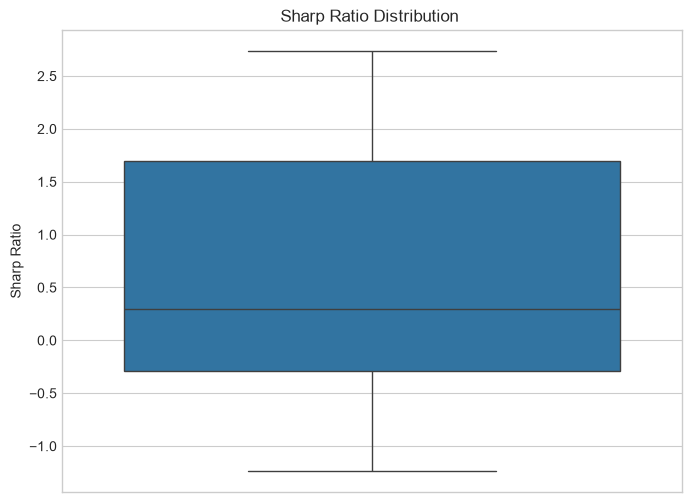

In [12]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=sharp_ratio_scores)
plt.ylabel('Sharp Ratio')
plt.title('Sharp Ratio Distribution ')
plt.show()


In [13]:
all_returns = np.concatenate(returns_scores)

np.mean(all_returns)/np.std(all_returns) * np.sqrt(252)


np.float64(0.7370087188414203)

In [14]:
def compute_concurrency(data :pd.DataFrame ,
                        events: pd.DataFrame,
                        end_time_col: str = 'end_time',
                       ) -> pd.DataFrame:

    # Ensure the DataFrame is sorted by index (start time)
    result = data.copy()
    result['n_concurent'] = 0
    for index, row in events.iterrows():
      result.loc[index : row[end_time_col], 'n_concurent'] += 1

    return result

In [15]:
labels

,End Time,Return of Label,Label
event_time,,,
2005-12-29,2006-01-03,0.0462,1
2006-01-03,2006-01-06,0.0207,1
2006-01-10,2006-01-11,0.0376,1
2006-01-11,2006-01-19,-0.0579,-1
2006-01-18,2006-01-19,-0.0418,-1
...,...,...,...
2025-07-21,2025-07-30,-0.0161,-1
2025-07-30,2025-08-01,-0.0319,-1
2025-08-01,2025-08-06,0.0537,1


In [16]:
compute_concurrency(appl , labels , 'End Time').head(20)

,Close,High,Low,Open,Volume,Ticker,Sector,SMA_20,SMA_50,EMA_20,EMA_50,RSI,MACD,MACD_Signal,Return,Lag_Return_1,Lag_Return_2,Lag_Return_3,Tomorrow_Return,n_concurent
Date,,,,,,,,,,,,,,,,,,,,
2005-11-14,1.8447,1.8606,1.8285,1.8474,369933200,AAPL,Information Technology,1.7430,1.6309,1.7531,1.6583,65.6885,0.0658,0.0600,-0.0015,0.0059,0.0178,0.0035,0.0135,0
2005-11-15,1.8697,1.8937,1.8450,1.8492,536841200,AAPL,Information Technology,1.7581,1.6390,1.7642,1.6666,67.7758,0.0670,0.0614,0.0135,-0.0015,0.0059,0.0178,0.0429,0
2005-11-16,1.9498,1.9531,1.8940,1.8958,784515200,AAPL,Information Technology,1.7731,1.6488,1.7818,1.6777,73.3848,0.0736,0.0638,0.0429,0.0135,-0.0015,0.0059,-0.0066,0
2005-11-17,1.9369,1.9777,1.9288,1.9690,676205600,AAPL,Information Technology,1.7857,1.6576,1.7966,1.6879,71.2342,0.0768,0.0664,-0.0066,0.0429,0.0135,-0.0015,0.0006,0
2005-11-18,1.9381,1.9642,1.9324,1.9606,524960800,AAPL,Information Technology,1.7990,1.6656,1.8101,1.6977,71.3184,0.0786,0.0689,0.0006,-0.0066,0.0429,0.0135,0.0062,0
2005-11-21,1.9501,1.9570,1.9129,1.9459,511711200,AAPL,Information Technology,1.8113,1.6737,1.8234,1.7076,72.1948,0.0801,0.0711,0.0062,0.0006,-0.0066,0.0429,0.0240,0
2005-11-22,1.9969,2.0041,1.9369,1.9465,540282400,AAPL,Information Technology,1.8269,1.6832,1.8399,1.7189,75.3577,0.0840,0.0737,0.0240,0.0062,0.0006,-0.0066,0.0089,0
2005-11-23,2.0146,2.0408,2.0020,2.0077,485853200,AAPL,Information Technology,1.8421,1.6937,1.8566,1.7305,76.4488,0.0876,0.0765,0.0089,0.0240,0.0062,0.0006,0.0332,0
2005-11-25,2.0816,2.0876,2.0264,2.0312,395012800,AAPL,Information Technology,1.8630,1.7054,1.8780,1.7443,80.0453,0.0947,0.0801,0.0332,0.0089,0.0240,0.0062,0.0046,0


In [17]:
def compute_pl_for_stratgy(data_row,  labeled_data , features , model , threshold = 0.55):
  label = model.predict(features)
  prob = np.max( model.predict_proba(features) , axis = 1)
  new_data = labeled_data.loc[features.index]
  new_data['label'] = label
  new_data['prob'] = prob
  new_data = new_data[new_data['prob'] > threshold]
  data_row['Strategy_return'] = 0.0
  for index, row in new_data.iterrows():
    size  =  row['label'] * row['prob']
    data_row.loc[index : row['End Time'],'Strategy_return' ]  += data_row.loc[index , 'Return'] * 1. / data_row.loc[index , 'n_concurent']  * size

  return data_row['Strategy_return']


In [18]:
n_samples = X.shape[0]

n_partitions = 8
k = 2
purge_size = 10


folds = combinatorial_purged_cv_indices(n_samples, n_partitions, k, purge_size)
data = compute_concurrency(appl , labels , 'End Time')

sharp_ratio_scores = []
returns_scores = []

for fold, (train_idx, test_idx) in enumerate(folds, 1):
    # Extract training and test data for this fold.
    X_train, y_train = X.iloc[train_idx , : ], y[train_idx]
    X_test, y_test = X.iloc[test_idx, : ], y[test_idx]

    # Fit the model using XGBRegressor.
    model = RandomForestClassifier(n_estimators=100, class_weight='balanced' , random_state=42)
    model.fit(X_train, y_train)
    returns = compute_pl_for_stratgy(data, apple_new , X_test, model).loc[X_test.index[0]: ]

    returns_scores.append(returns.values)
    sr = np.mean(returns)/np.std(returns) * np.sqrt(252)
    sharp_ratio_scores.append(sr)
    print(f"Fold {fold} - Sharp Ratio: {sr:.4f}")



Fold 1 - Sharp Ratio: 1.8222
Fold 2 - Sharp Ratio: 1.5711
Fold 3 - Sharp Ratio: 1.7828
Fold 4 - Sharp Ratio: 2.0403
Fold 5 - Sharp Ratio: 2.5112
Fold 6 - Sharp Ratio: 0.8135
Fold 7 - Sharp Ratio: 1.3627
Fold 8 - Sharp Ratio: 0.5975
Fold 9 - Sharp Ratio: 1.6640
Fold 10 - Sharp Ratio: 0.4367
Fold 11 - Sharp Ratio: 1.0721
Fold 12 - Sharp Ratio: 0.6988
Fold 13 - Sharp Ratio: 0.1072
Fold 14 - Sharp Ratio: 3.5406
Fold 15 - Sharp Ratio: -0.2560
Fold 16 - Sharp Ratio: 2.1828
Fold 17 - Sharp Ratio: 0.2945
Fold 18 - Sharp Ratio: -0.4934
Fold 19 - Sharp Ratio: 3.3658
Fold 20 - Sharp Ratio: 2.6649
Fold 21 - Sharp Ratio: 1.7961
Fold 22 - Sharp Ratio: 0.3187
Fold 23 - Sharp Ratio: 0.2003
Fold 24 - Sharp Ratio: 0.7416
Fold 25 - Sharp Ratio: 0.1540
Fold 26 - Sharp Ratio: 1.8039
Fold 27 - Sharp Ratio: -0.2630
Fold 28 - Sharp Ratio: -1.0208


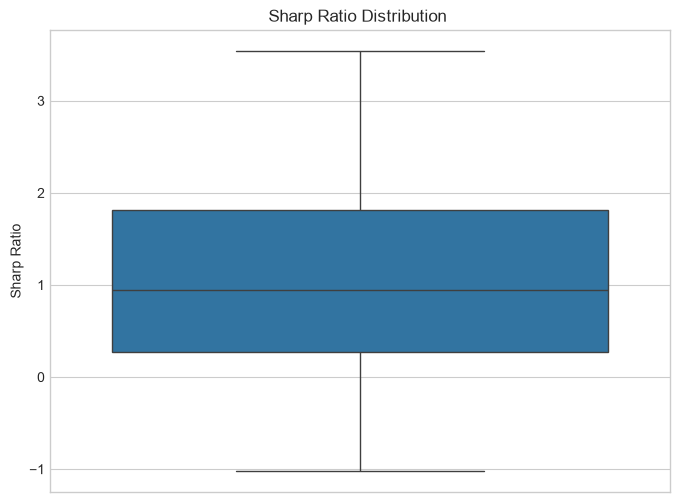

In [19]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=sharp_ratio_scores)
plt.ylabel('Sharp Ratio')
plt.title('Sharp Ratio Distribution ')
plt.show()


# Deflated Sharp Ratio

## 1. Sampling Statistics of the Sharpe Ratio (Lo)

Assume i.i.d. returns with mean $\mu$ and standard deviation $\sigma$ and Sharpe $SR=\mu/\sigma$.
For $T$ observations the sample Sharpe $\hat{SR}$ is asymptotically normal

$$
\sqrt{T}(\hat{SR}-SR)\xrightarrow{d}Z
$$

$$
Z \text{ is Normal with mean } 0 \text{ and variance } 1+\tfrac{1}{2}SR^2
$$

$$
\operatorname{Var}(\hat{SR}) \approx \frac{1+\tfrac{1}{2}SR^2}{T}
$$

$$
\operatorname{se}(\hat{SR}) \approx \sqrt{\frac{1+\tfrac{1}{2}SR^2}{T-1}}
$$

---

## 2. Dropping Normality (Mertens)

If returns have standardized skewness $\gamma_3$ and kurtosis $\gamma_4$ with $\gamma_4=3$ under normality a delta method derivation gives

$$
\operatorname{Var}(\hat{SR}) \approx \frac{1 - \gamma_3 SR + \tfrac{\gamma_4-1}{4}SR^2}{T}
$$

$$
\operatorname{se}(\hat{SR}) \approx \sqrt{\frac{1 - \gamma_3 SR + \tfrac{\gamma_4-1}{4}SR^2}{T-1}}
$$

This widens or narrows uncertainty according to skew and tail heaviness.

---

## 3. The Probabilistic Sharpe Ratio (PSR)

Given a benchmark $SR^*$ often $0$ the PSR is the probability that the true Sharpe exceeds $SR^*$

$$
\mathrm{PSR}(SR^*) =
\Phi\left(
\frac{\hat{SR}-SR^*}{\sqrt{\bigl(1-\hat{\gamma}_3 \hat{SR} + \tfrac{\hat{\gamma}_4-1}{4}\hat{SR}^{2}\bigr)/(T-1)}}
\right)
$$

Here $\Phi$ is the standard Normal CDF and $\hat{\gamma}_3$ and $\hat{\gamma}_4$ are sample skewness and kurtosis.

---

## 4. Minimum Track Record Length (MinTRL)

For a target confidence $1-\alpha$ that $SR>SR^*$ solve the PSR expression for $T$.
Using sample estimates this yields

$$
\widehat{\mathrm{MinTRL}} = 1 +
\left(1 - \hat{\gamma}_3 \hat{SR} + \frac{\hat{\gamma}_4-1}{4}\hat{SR}^2\right)
\left(\frac{Z_\alpha}{\hat{SR}-SR^*}\right)^2
$$

with $Z_\alpha=\Phi^{-1}(1-\alpha)$

---

## 5. Distribution of the Maximum of Normal Draws

If you run $N$ independent trials whose Sharpe estimates are approximately normal with cross trial mean $\overline{\hat{SR}}$ and standard deviation $\hat{\sigma}_{\hat{SR}}$ the expected maximum rises with $N$.
An approximation from extreme value considerations is

$$
\mathbb{E}\bigl[\max_{1\le i\le N}\hat{SR}_i\bigr]
\approx
\overline{\hat{SR}} +
\hat{\sigma}_{\hat{SR}}
\left[
(1-\gamma)\Phi^{-1}\!\Bigl(1-\tfrac{1}{N}\Bigr)
+\gamma\Phi^{-1}\!\Bigl(1-\tfrac{1}{N e}\Bigr)
\right]
$$

Here $\gamma \approx 0.5772$ is the Euler–Mascheroni constant and $e$ is Euler's number.
This gives a practical lucky winner level expected purely from multiple testing.

---

## 6. Deflated Sharpe Ratio (DSR)

Set the multiple testing hurdle to the expected noise maximum call that value $SR_0$.
The Deflated Sharpe Ratio is the PSR evaluated at this threshold

$$
\mathrm{DSR} =
\Phi\left(
\frac{(\hat{SR}-SR_0)\sqrt{T-1}}
{\sqrt{1-\hat{\gamma}_3 SR_0 + \tfrac{\hat{\gamma}_4-1}{4}SR_0^{2}}}
\right)
$$

DSR is the probability that the observed $\hat{SR}$ reflects skill beyond what is expected from trying $N$ variants while accounting for skewness kurtosis and finite sample size.


In [ ]:
# This code is from RiskLabAI

import numpy as np
from scipy import stats as ss


def probabilistic_sharpe_ratio(
        observed_sharpe_ratio: float,
        benchmark_sharpe_ratio: float,
        number_of_returns: int,
        skewness_of_returns: float = 0,
        kurtosis_of_returns: float = 3,
        return_test_statistic: bool = False,
) -> float:
    """
    Calculates the Probabilistic Sharpe Ratio (PSR) based on observed and benchmark Sharpe ratios.

    The PSR provides a means to test whether a track record would have achieved an observed
    level of outperformance due to skill or luck. It is calculated using:

    .. math::
        \frac{(\hat{SR} - SR^*) \sqrt{T-1}}{\sqrt{1 - S \hat{SR} + \frac{K-1}{4} \hat{SR}^2}}

    Where:
    - \(\hat{SR}\) is the observed Sharpe ratio
    - \(SR^*\) is the benchmark Sharpe ratio
    - \(T\) is the number of returns
    - \(S\) is the skewness of returns
    - \(K\) is the kurtosis of returns

    :param observed_sharpe_ratio: The observed Sharpe ratio.
    :param benchmark_sharpe_ratio: The benchmark Sharpe ratio.
    :param number_of_returns: The number of return observations.
    :param skewness_of_returns: The skewness of the returns (default = 0).
    :param kurtosis_of_returns: The kurtosis of the returns (default = 3).
    :param return_test_statistic: Return the test statistic instead of the CDF value.
    :return: The Probabilistic Sharpe Ratio.
    """
    test_value = (
        (observed_sharpe_ratio - benchmark_sharpe_ratio) * np.sqrt(number_of_returns - 1)
    ) / (
        (1 - skewness_of_returns * observed_sharpe_ratio
        + (kurtosis_of_returns - 1) / 4 * observed_sharpe_ratio ** 2) ** (1 / 2)
    )

    if return_test_statistic:
        return test_value

    else:
        return ss.norm.cdf(test_value)

def benchmark_sharpe_ratio(
        sharpe_ratio_estimates: list
) -> float:
    """
    Calculates the Benchmark Sharpe Ratio based on Sharpe ratio estimates.

    The benchmark Sharpe ratio is computed using:

    .. math::
        \sigma_{SR} \left[ (1 - \gamma) \Phi^{-1}(1 - \frac{1}{N}) + \gamma \Phi^{-1}(1 - \frac{1}{N} e^{-1}) \right]

    Where:
    - \(\sigma_{SR}\) is the standard deviation of Sharpe ratio estimates
    - \(\gamma\) is the Euler's constant
    - \(\Phi^{-1}\) is the inverse of the cumulative distribution function (CDF) of a standard normal distribution
    - \(N\) is the number of Sharpe ratio estimates

    :param sharpe_ratio_estimates: List of Sharpe ratio estimates.
    :return: The Benchmark Sharpe Ratio.
    """
    standard_deviation = np.array(sharpe_ratio_estimates).std()
    benchmark_value = (
        standard_deviation * (
            (1 - np.euler_gamma) * ss.norm.ppf(1 - 1 / len(sharpe_ratio_estimates))
            + np.euler_gamma * ss.norm.ppf(1 - 1 / len(sharpe_ratio_estimates) * np.e ** (-1))
        )
    )

    return benchmark_value